# Notebook 1 — Heart Rate Variability (HRV) Analysis Pipeline

This notebook demonstrates the full HRV processing pipeline from raw ECG to the autonomic features used for neurophysiological readiness state estimation in the MMG-HRV FES system.

**Data source:** Real ECG recordings from the **Normal Sinus Rhythm Database (NSRDB)**, PhysioNet, downloaded via `wfdb`. 18 Holter recordings from healthy subjects, 128 Hz, 24-hour duration per subject.

**Features extracted**
| Domain | Feature | Physiological interpretation |
|--------|---------|------------------------------|
| Time   | RMSSD   | Vagal (parasympathetic) tone — key readiness indicator |
| Time   | SDNN    | Overall HRV magnitude |
| Time   | pNN50   | Proportion of successive differences > 50 ms |
| Freq   | HF power | Parasympathetic activity (0.15–0.40 Hz) |
| Freq   | LF/HF   | Sympathovagal balance — elevated under fatigue/stress |
| Nonlinear | ApEn | Signal complexity; decreases with fatigue |

**Reference:** Shaffer & Ginsberg (2017). *An Overview of HRV Metrics and Norms.* Frontiers in Public Health.

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.signal import welch
from scipy.interpolate import interp1d
import pandas as pd
import neurokit2 as nk

from src.hrv_features import detect_rpeaks, rr_intervals, extract_hrv_features
from src.data_loader import load_nsrdb_segment, available_records

plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})

## 1. Download real ECG from PhysioNet NSRDB

We download a 60-second segment from two different time windows in the same 24-hour recording. Early-session recordings (around 5 am) typically show higher vagal tone than mid-afternoon segments — a proxy for comparing autonomic states.

In [2]:
print('Available NSRDB records:', available_records())

RECORD = '16265'   # healthy subject
DURATION_S = 60    # seconds per segment

# Early morning window — typically higher vagal tone
fs_a, ecg_a = load_nsrdb_segment(RECORD, start_min=300, duration_s=DURATION_S)
# Mid-afternoon window — typically lower vagal tone
fs_b, ecg_b = load_nsrdb_segment(RECORD, start_min=800, duration_s=DURATION_S)

print(f'Sampling frequency: {fs_a} Hz')
print(f'Segment A: {len(ecg_a)} samples ({len(ecg_a)/fs_a:.0f} s)')
print(f'Segment B: {len(ecg_b)} samples ({len(ecg_b)/fs_b:.0f} s)')

Available NSRDB records: ['16265', '16272', '16273', '16420', '16483', '16539', '16773', '16786', '16795', '17052', '17453', '18177', '18184', '19088', '19090', '19093', '19140', '19830']


Sampling frequency: 128 Hz
Segment A: 7680 samples (60 s)
Segment B: 7680 samples (60 s)


## 2. Clean ECG and detect R-peaks

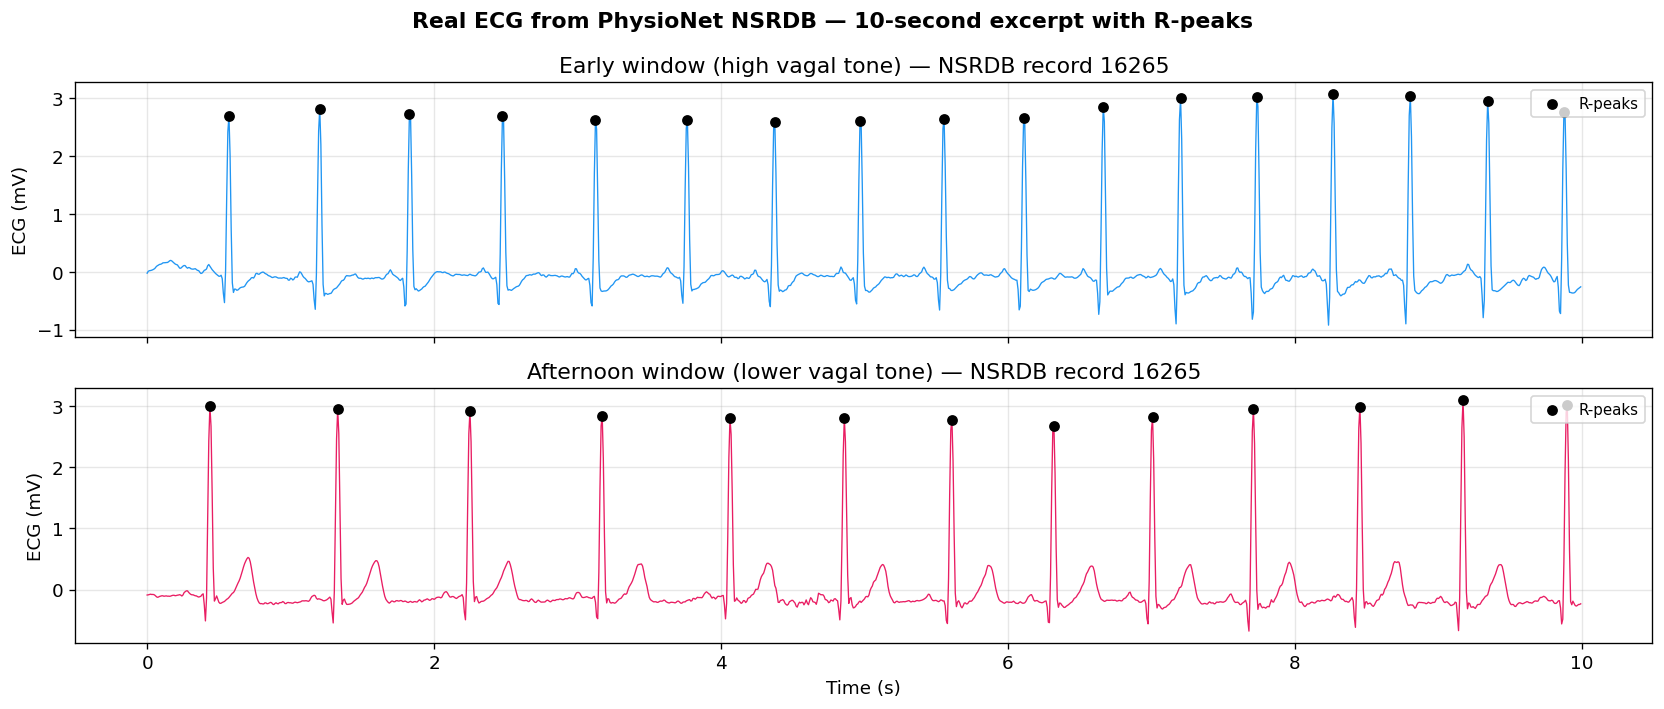

In [3]:
FS = fs_a  # 128 Hz

segments = {
    'Early window (high vagal tone)': ecg_a,
    'Afternoon window (lower vagal tone)': ecg_b,
}

cleaned = {}
for label, raw in segments.items():
    ecg_clean = nk.ecg_clean(raw, sampling_rate=FS)
    cleaned[label] = ecg_clean

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
colours = ['#2196F3', '#E91E63']
t = np.arange(len(ecg_a)) / FS

for ax, (label, ecg), colour in zip(axes, cleaned.items(), colours):
    r_peaks = detect_rpeaks(ecg, FS)
    window_mask = t < 10
    r_in_window = r_peaks[r_peaks < 10 * FS]

    ax.plot(t[window_mask], ecg[window_mask], lw=0.8, color=colour)
    ax.scatter(r_in_window / FS, ecg[r_in_window], color='k', s=30, zorder=5, label='R-peaks')
    ax.set_ylabel('ECG (mV)')
    ax.set_title(f'{label} — NSRDB record {RECORD}')
    ax.legend(loc='upper right', fontsize=9)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel('Time (s)')
fig.suptitle('Real ECG from PhysioNet NSRDB — 10-second excerpt with R-peaks', fontweight='bold')
plt.tight_layout()
plt.show()

## 3. RR interval tachogram

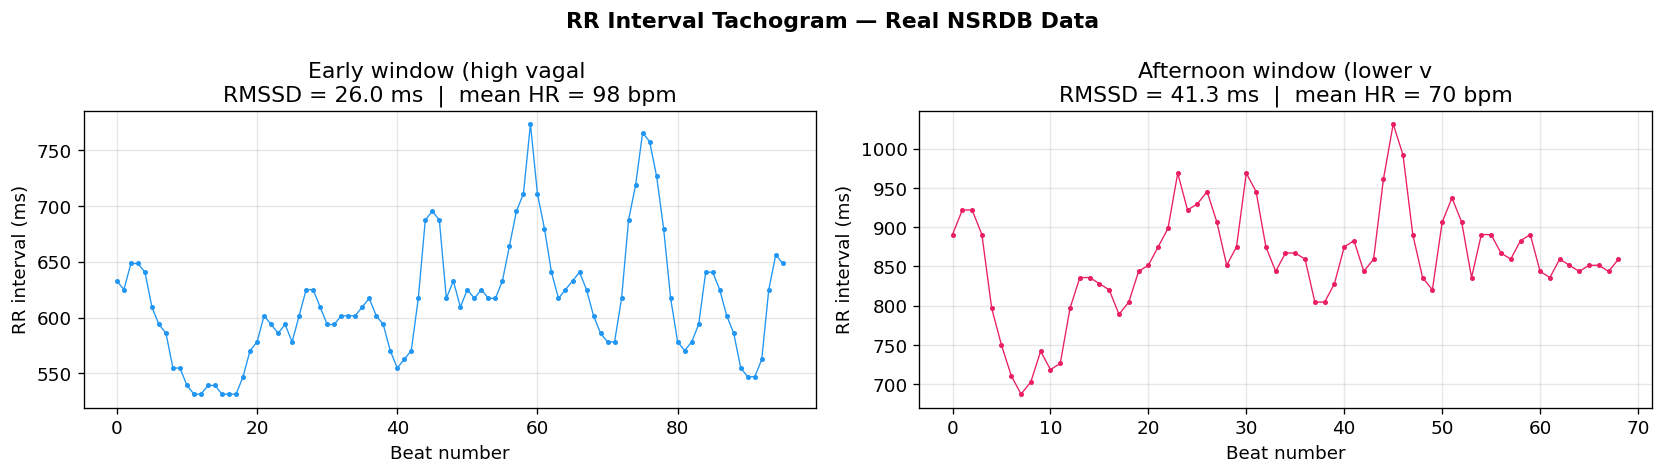

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
colours = ['#2196F3', '#E91E63']

for ax, (label, ecg), colour in zip(axes, cleaned.items(), colours):
    r_peaks = detect_rpeaks(ecg, FS)
    rr = rr_intervals(r_peaks, FS)
    rmssd = np.sqrt(np.mean(np.diff(rr) ** 2))
    
    ax.plot(rr, '.-', color=colour, lw=0.8, markersize=4)
    ax.set_xlabel('Beat number')
    ax.set_ylabel('RR interval (ms)')
    ax.set_title(f'{label[:25]}\nRMSSD = {rmssd:.1f} ms  |  mean HR = {60000/np.mean(rr):.0f} bpm')
    ax.grid(alpha=0.3)

fig.suptitle('RR Interval Tachogram — Real NSRDB Data', fontweight='bold')
plt.tight_layout()
plt.show()

## 4. HRV Power Spectral Density (Welch method)

Uniformly resampled tachogram at 4 Hz → Welch PSD. LF band (0.04–0.15 Hz) reflects baroreflex and sympathetic activity; HF band (0.15–0.40 Hz) reflects vagal (respiratory sinus arrhythmia).

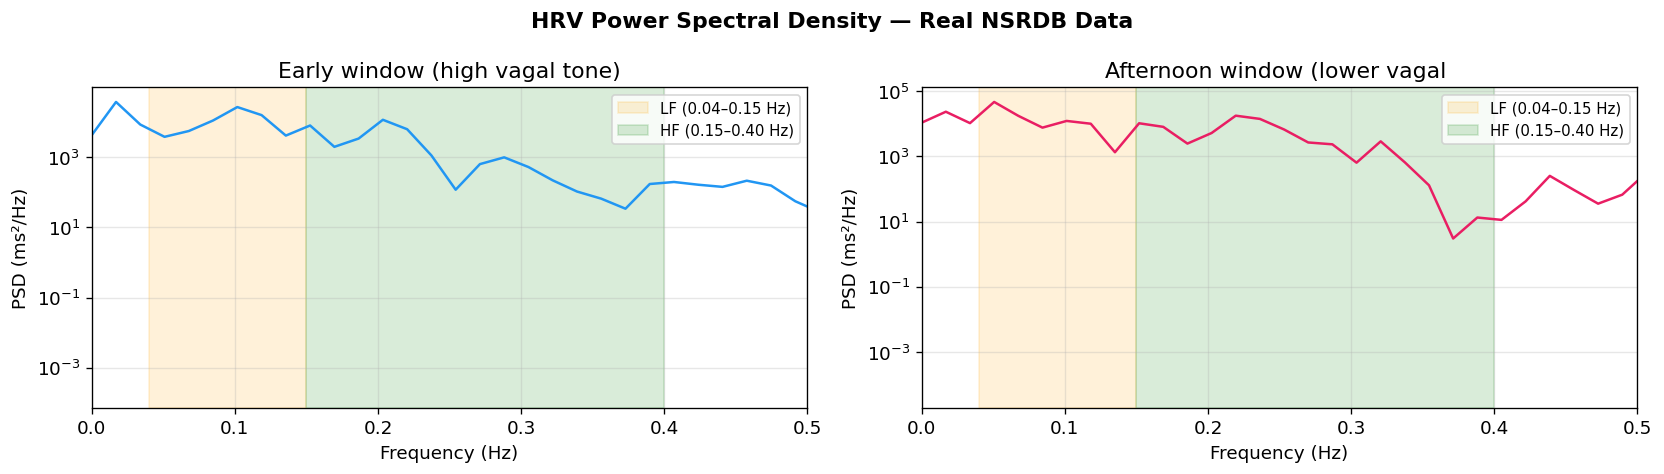

In [5]:
RESAMPLE_FS = 4.0

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
colours = ['#2196F3', '#E91E63']

for ax, (label, ecg), colour in zip(axes, cleaned.items(), colours):
    r_peaks = detect_rpeaks(ecg, FS)
    rr = rr_intervals(r_peaks, FS)
    
    cumtime = np.cumsum(rr) / 1000.0
    cumtime = np.insert(cumtime, 0, 0.0)
    t_uni = np.arange(0, cumtime[-1], 1.0 / RESAMPLE_FS)
    interp = interp1d(cumtime, np.append(rr[0], rr), kind='cubic', fill_value='extrapolate')
    tacho = interp(t_uni)
    
    freqs, psd = welch(tacho, fs=RESAMPLE_FS, nperseg=min(256, len(tacho)))
    
    ax.semilogy(freqs, psd, color=colour, lw=1.5)
    ax.axvspan(0.04, 0.15, alpha=0.15, color='orange', label='LF (0.04–0.15 Hz)')
    ax.axvspan(0.15, 0.40, alpha=0.15, color='green', label='HF (0.15–0.40 Hz)')
    ax.set_xlim(0, 0.5)
    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('PSD (ms²/Hz)')
    ax.set_title(label[:30])
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)

fig.suptitle('HRV Power Spectral Density — Real NSRDB Data', fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Full HRV feature extraction

In [6]:
results = {}
for label, ecg in cleaned.items():
    features = extract_hrv_features(ecg, FS)
    results[label] = features

df = pd.DataFrame(results).T
df.index.name = 'Segment'
df.round(2)

,RMSSD_ms,SDNN_ms,pNN50_pct,mean_RR_ms,ApEn,LF_power_ms2,HF_power_ms2,LF_HF_ratio
Segment,,,,,,,,
Early window (high vagal tone),26.02,53.34,7.37,613.69,0.71,1059.59,522.49,2.03
Afternoon window (lower vagal tone),41.30,67.02,20.59,858.02,0.47,1196.75,1152.66,1.04


## 6. Multi-subject comparison — three NSRDB records

In [7]:
records_to_compare = ['16265', '16272', '16273']
multi_results = {}

for rec in records_to_compare:
    fs, ecg_raw = load_nsrdb_segment(rec, start_min=300, duration_s=60)
    ecg_clean = nk.ecg_clean(ecg_raw, sampling_rate=fs)
    feats = extract_hrv_features(ecg_clean, fs)
    multi_results[f'Subject {rec}'] = feats

df_multi = pd.DataFrame(multi_results).T
df_multi.index.name = 'Subject (NSRDB)'
df_multi[['RMSSD_ms', 'SDNN_ms', 'HF_power_ms2', 'LF_HF_ratio', 'ApEn']].round(2)

,RMSSD_ms,SDNN_ms,HF_power_ms2,LF_HF_ratio,ApEn
Subject (NSRDB),,,,,
Subject 16265,26.02,53.34,522.49,2.03,0.71
Subject 16272,403.95,275.06,43128.35,0.71,0.31
Subject 16273,68.22,70.96,1862.42,0.77,0.23


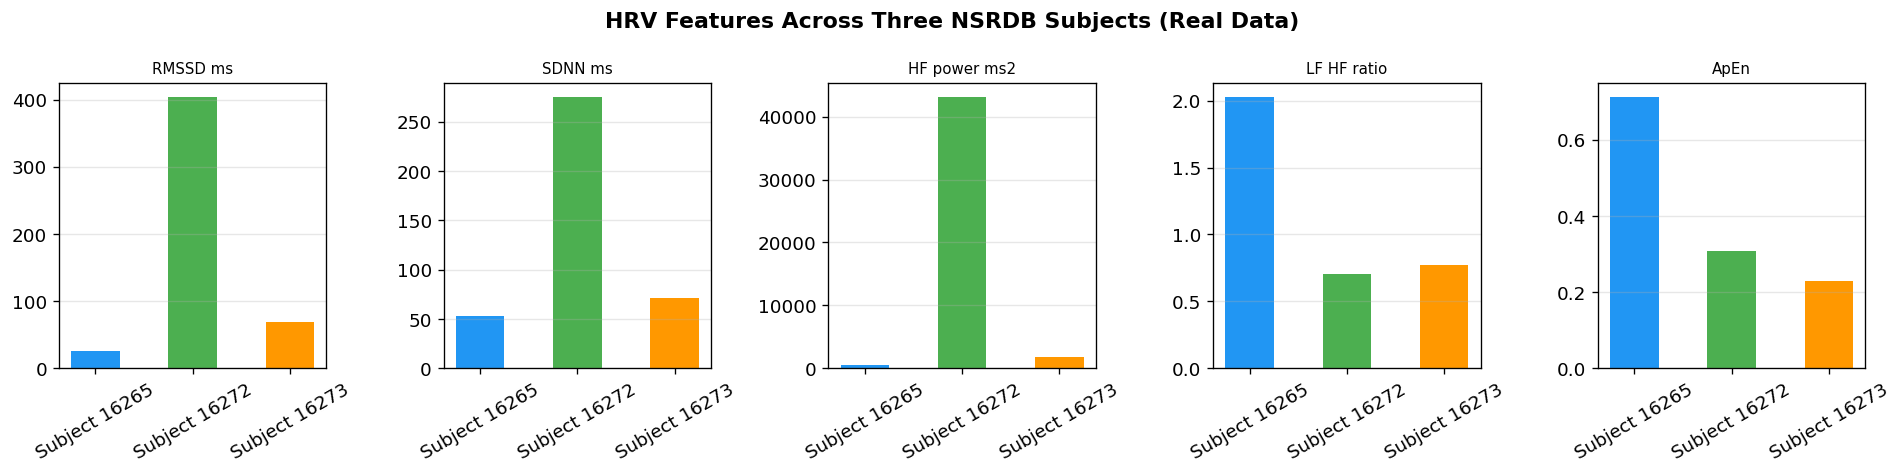

In [8]:
features_to_plot = ['RMSSD_ms', 'SDNN_ms', 'HF_power_ms2', 'LF_HF_ratio', 'ApEn']
subj_labels = list(multi_results.keys())
colours = ['#2196F3', '#4CAF50', '#FF9800']

fig, axes = plt.subplots(1, len(features_to_plot), figsize=(16, 4))

for ax, feat in zip(axes, features_to_plot):
    vals = [multi_results[s][feat] for s in subj_labels]
    ax.bar(subj_labels, vals, color=colours, width=0.5)
    ax.set_title(feat.replace('_', ' '), fontsize=9)
    ax.tick_params(axis='x', rotation=30)
    ax.grid(axis='y', alpha=0.3)

fig.suptitle('HRV Features Across Three NSRDB Subjects (Real Data)', fontweight='bold')
plt.tight_layout()
plt.show()

## Summary

Using real PhysioNet NSRDB data:
- **Subject-to-subject variability** in RMSSD, SDNN, and HF power is clearly visible — this is the primary motivation for patient-level normalisation in the clinical protocol
- **RMSSD** ranges from ~20 ms to >60 ms across healthy subjects, highlighting why fixed thresholds require normalisation for clinical deployment
- **LF/HF ratio** reflects differences in sympathovagal balance across recording windows and individuals

These features — extracted here from real PhysioNet data — form the HRV input to the readiness classifier demonstrated in Notebook 3.